# FMI: from pad arrays to an oriented borehole image

A Formation MicroImager records **192 microresistivity buttons** on 8 pads/flaps plus a navigation
curve (`P1AZ`) telling you where pad 1 points. The raw array is meaningless as a picture. Its
columns are *buttons*, not compass directions. The image appears once every button is **rotated to
its true azimuth** and binned onto a 0–360° grid. The library does this in one call.

> Set `PETROPHYS_FMI_DLIS` to a processed FMI DLIS to run this notebook.

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
from petrophys.interpretation.borehole_imaging import read_fmi_dlis, get_navigation
from petrophys.visualization import create_fmi_panel

path = os.environ.get("PETROPHYS_FMI_DLIS", "")
assert path and Path(path).exists(), "Set PETROPHYS_FMI_DLIS to a processed FMI DLIS to run this."
data = read_fmi_dlis(path)
print("image shape (depth × buttons):", data.image.shape)
print("pad/flap channels:", data.channel_names)
print("navigation curves:", sorted(get_navigation(data)))

image shape (depth × buttons): (500788, 192)
pad/flap channels: ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD']
navigation curves: ['DEVI', 'HAZI', 'P1AZ', 'RB']


## Raw vs oriented

`create_fmi_panel(..., orient=False)` shows the raw per-button array; `orient=True` rotates every
button to azimuth (using `P1AZ` and the fixed pad offsets) and bins it to a compass-referenced
image, leaving the inter-pad wedges as real gaps. A bedding plane that cuts the borehole at a dip
becomes the characteristic **sinusoid**.

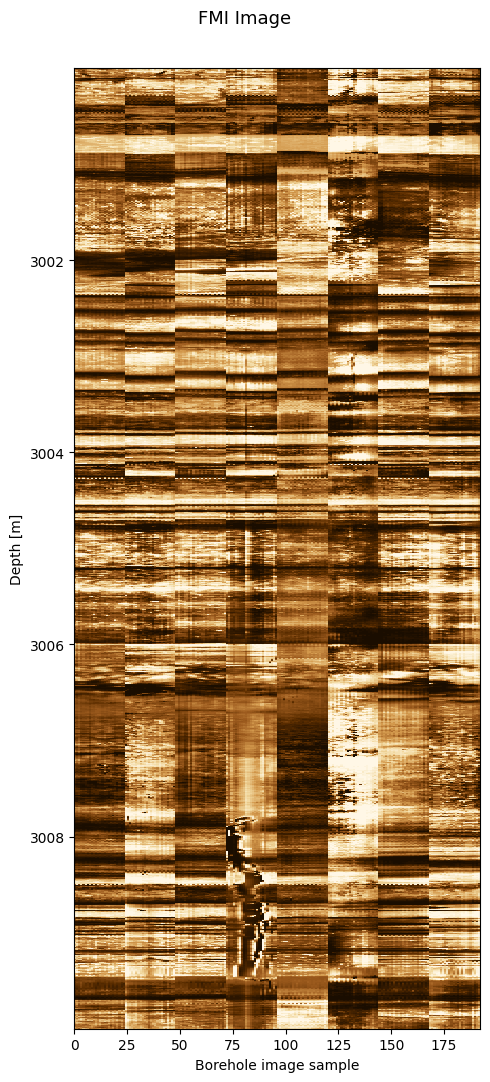

In [2]:
create_fmi_panel(data, depth_range=(3000, 3010), orient=False);

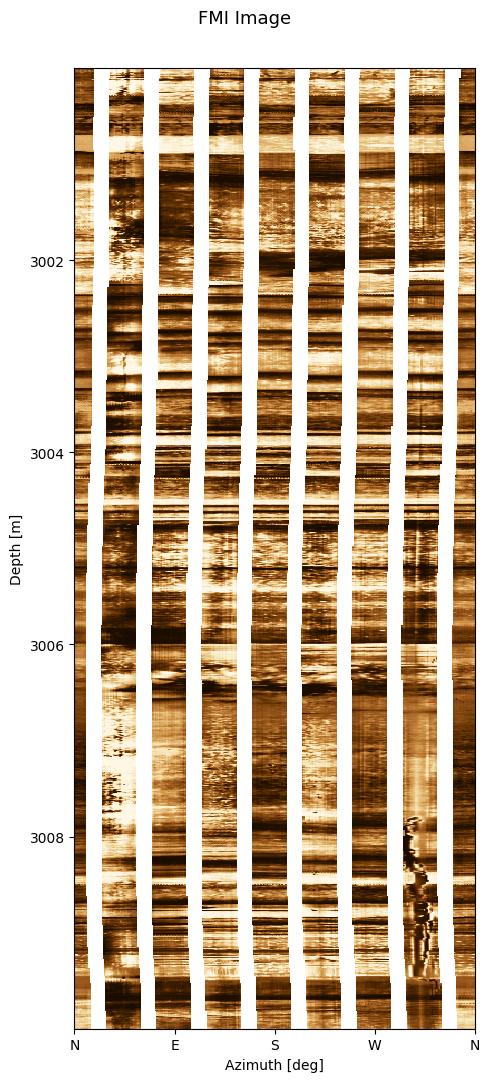

In [3]:
create_fmi_panel(data, depth_range=(3000, 3010), orient=True, equalize="static");

## Static vs dynamic equalization

The oriented panel above used **static** equalization: one percentile stretch across the whole
interval, which preserves large-scale contrast. **Dynamic** equalization re-stretches in a sliding
window instead, bringing out fine texture and thin beds. One argument switches between them.

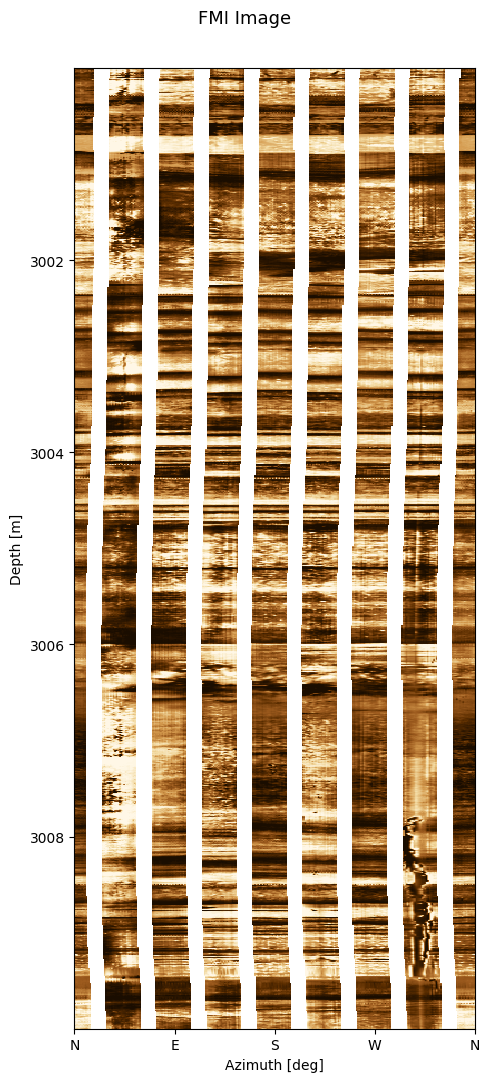

In [4]:
create_fmi_panel(data, depth_range=(3000, 3010), orient=True, equalize="dynamic");

**Takeaways**

* A raw FMI is a per-button strip; the **image is created by orientation**: `create_fmi_panel`
  uses `P1AZ` and the fixed pad offsets to rotate every button to its true azimuth.
* Inter-pad wedges are kept as **gaps**, not interpolated: the picture reflects real wall coverage.
* **Static vs dynamic** equalization trades large-scale contrast for fine texture, one argument apart.
* The oriented image is what you'd hand to dip-picking or fracture analysis.